In [78]:
import os
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [79]:
with open('judge stats for visualisation.csv', newline='') as file:
    reader = csv.reader(file)
    judgestats = (list(reader))

In [80]:
#removing formatting character at start of first line
judgestats[0][0]=judgestats[0][0][1:]

In [81]:
#Defining pairs. Order tracks order in source file. Pairs are presented alphabetically in the table so changing
#the numbers in this list will reorder pairs in the table, but order in this list needs to remain unchanged
#to ensure data is loaded correctly
pairs = ["2. P2max", "1. Ppop", "4. Claude vs.\nGPT-4o", "3. Claude vs.\nGemini", "5. Claude vs.\nGPT-5.1", "6. GPT-4o vs.\nGemini", "8. GPT-4o vs.\nGPT-5.1", "7. Gemini vs.\nGPT-5.1"]


In [82]:
#Copy data into formatted data dictionary

data = []

for line in judgestats:
    for pair in pairs:
        mean_val = float(line[2+(3*pairs.index(pair))])
        ci_lower = float(line[3+(3*pairs.index(pair))])
        ci_upper = float(line[4+(3*pairs.index(pair))])

        data.append({
            'Tool': line[0],
            'Trial_Pair': pair,
            'Condition': line[1],
            'Mean': mean_val,
            'CI_Lower': ci_lower,
            'CI_Upper': ci_upper
        })


In [83]:
#create list of Judges (extracted from labels in file, so changing labels in file will change labels in table)
judges=[]
for a in data:
    if a['Tool'] not in judges:
        judges.append(a['Tool'])

In [84]:
# defining trial pairs and conditions for use in graph
trial_pairs = pairs
conditions = ['Without original arguments', 'With original arguments']

In [85]:
#reorder judges by values of Ppop
judgestemp=[]
for a in judges:
    ppop=0
    for b in data:
        if b['Tool']==a and b['Condition']=='Without original arguments' and b['Trial_Pair']=='1. Ppop':
            ppop=b['Mean']
    judgestemp.append([a, ppop])
    judgestemp = sorted(judgestemp, key=lambda x: x[1], reverse=False)

for a in range(0,len(judges)):
    judges[a]=judgestemp[a][0]

In [86]:
# Load data into dataframe

df = pd.DataFrame(data)

# Ensure Tool is categorical for correct sorting order
df['Tool'] = pd.Categorical(df['Tool'], categories=judges, ordered=True)
df = df.sort_values(['Trial_Pair', 'Tool'])

name_map = {
	'claude-haiku-4-5-20251001_8k-thinking': 'Claude-haiku-4.5_8k-thinking',
	'claude-haiku-4-5-20251001_nothinking': 'Claude-haiku-4.5_nothinking',
	'claude-sonnet-4-5-20250929_1k-thinking': 'Claude-sonnet-4.5_1k-thinking',
	'claude-sonnet-4-5-20250929_8k-thinking': 'Claude-sonnet-4.5_8k-thinking',
	'deepseek-chat_defaults': 'Deepseek-chat',
	'deepseek-reasoner_defaults': 'Deepseek-reasoner',
	'gemini-2.5-flash-lite_nonreasoning': 'Gemini-2.5-flash-lite_nonreasoning',
	'gemini-2.5-flash-lite_reasoning': 'Gemini-2.5-flash-lite_reasoning',
	'gemini-3-pro-preview_1k-thinking': 'Gemini-3-pro-preview_1k-thinking',
	'gemini-3-pro-preview_8k-thinking': 'Gemini-3-pro-preview_8k-thinking',
	'gpt-5-nano_medium-reasoning': 'GPT-5-nano_medium-reasoning',
	'gpt-5-nano_minimal-reasoning': 'GPT-5-nano_minimal-reasoning',
	'gpt-5.1_low-reasoning': 'GPT-5.1_low-reasoning',
	'gpt-5.1_medium-reasoning': 'GPT-5.1_medium-reasoning',
	'mistralai/Magistral-Small-2506_defaults': 'Magistral-Small-2506',
	'mistralai/Mistral-Small-3.2-24B-Instruct-2506_defaults': 'Mistral-Small-3.2-24B-Instruct-2506',
	'Qwen/Qwen3-32B_nothinking': 'Qwen3-32B_nothinking',
	'Qwen/Qwen3-32B_thinking': 'Qwen3-32B_thinking',
	'QWen/Qwen3-8B_nothinking': 'Qwen3-8B_nothinking',
	'QWen/Qwen3-8B_thinking': 'Qwen3-8B_thinking',
}

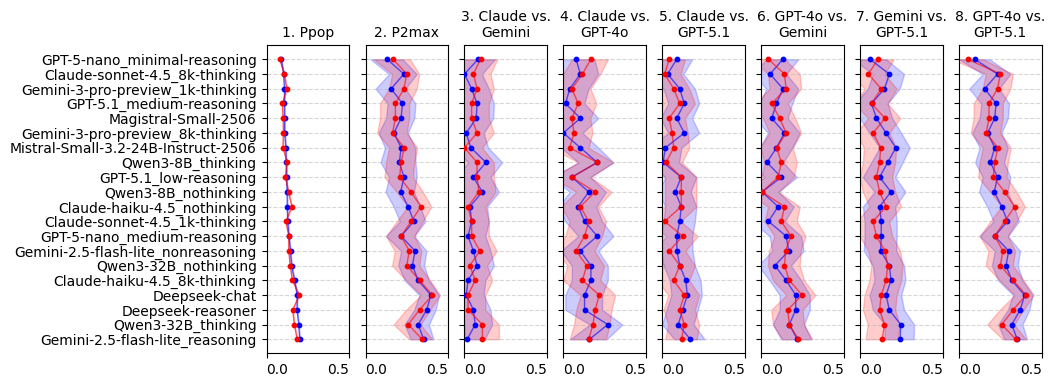

In [87]:
import matplotlib.pyplot as plt

# Generate Graph

def create_chart(dataframe):

    # Setup the plot: 1 row, 6 columns, sharing the Y axis (Tools)
    unique_pairs = sorted(dataframe['Trial_Pair'].unique())
    num_cols = len(unique_pairs)

    fig, axes = plt.subplots(nrows=1, ncols=num_cols, figsize=(10, 4), sharey=True)

    # Define colors
    colors = {'Without original arguments': 'blue', 'With original arguments': 'red'}

    # Map tools to Y-axis positions
    tools_ordered = dataframe['Tool'].cat.categories
    y_pos = np.arange(len(tools_ordered))

    # Loop through each trial pair (column)
    for i, pair in enumerate(unique_pairs):
        ax = axes[i] if num_cols > 1 else axes
        pair_data = dataframe[dataframe['Trial_Pair'] == pair]

        for cond in conditions:
            # Extract data for this condition and sort by Tool
            cond_data = pair_data[pair_data['Condition'] == cond].sort_values('Tool')

            means = cond_data['Mean'].values
            ci_lowers = cond_data['CI_Lower'].values
            ci_uppers = cond_data['CI_Upper'].values

            # 1. Plot shaded margin for confidence interval
            # fill_betweenx fills horizontally between x-values for given y-values
            ax.fill_betweenx(y_pos, ci_lowers, ci_uppers, color=colors[cond], alpha=0.2)

            # 2. Plot line linking means vertically
            ax.plot(means, y_pos, color=colors[cond], linestyle='-', linewidth=1, alpha=0.6)

            # 3. Plot solid dots for means
            ax.scatter(means, y_pos, color=colors[cond], label=cond, s=10, zorder=3)

        # Chart formatting
        # ax.set_title(pair) # Increase title font size
        ax.set_title(pair, fontsize=10)
        ax.set_xlim(0, 0.5)  # Fixed scale 0 to 0.5
        # ax.set_xlabel('Result', fontsize=10) # Increase x-axis label font size
        ax.grid(True, linestyle='--', alpha=0.5)

        # Configure Y-axis only on the leftmost plot
        if i == 0:
            ax.set_yticks(y_pos)
            ax.set_yticklabels([name_map[name] for name in tools_ordered]) # Increase y-tick label font size
            ax.invert_yaxis() # Invert so Tool 1 is at the top
#            ax.set_ylabel("Tools", fontsize=14) # Increase y-axis label font size
            # Add legend to the first plot
#            ax.legend(loc='upper right', fontsize='large') # Increase legend font size

        # ax.tick_params(axis='x')

        xlabels = ax.get_xticklabels()

        xlabels[0].set_ha('left')    # 0.0 extends to the right of its tick
        xlabels[-1].set_ha('right')  # 0.5 extends to the left of its tick

    # plt.subplots_adjust(
    #     left=0.18,
    #     right=0.99,
    #     bottom=0.20,
    #     top=0.80,
    #     wspace=0.12
    # )

    # plt.tight_layout()
    plt.show()

    fig.savefig("/Users/daithi/Downloads/chart.pdf", bbox_inches="tight")

# (iii) Run the code
if __name__ == "__main__":
    create_chart(df)

In [88]:
len(unique_pairs)

NameError: name 'unique_pairs' is not defined

In [ ]:
advwinres=[0,0,0,0]
advtryres=[0,0,0,0]
for a in fullres:
    advwinres[advocates.index(a[9])]+=1
    advtryres[advocates.index(a[2])]+=1
    advtryres[advocates.index(a[4])]+=1


In [ ]:
advall=[]
advall.append(advwinres)
advall.append(advtryres)
temp=[0,0,0,0]
for a in range(0,4):
    temp[a]=advall[0][a]/advall[1][a]
advall.append(temp)

In [ ]:
advall

[[5659, 3869, 5805, 8632],
 [11146, 11865, 11862, 13057],
 [0.5077157724744303,
  0.3260851243152128,
  0.48937784522003036,
  0.6611013249597917]]

In [ ]:
advocates

['claude-sonnet-4.5', 'gpt-4o', 'gemini-3-pro-preview', 'gpt-5.1']

In [ ]:
for a in range (0, 4):
    bint = scipy.stats.binomtest(advall[0][a], advall[1][a])
    print(bint.pvalue)

0.10529090090635725
1.434e-320
0.02118530970245047
6.596534952351908e-302
